# Klasifikasi Kategori Produk E-Commerce: ANN vs Naive Bayes vs SVM vs Random Forest

Notebook ini membandingkan empat algoritma klasifikasi teks, yaitu **Artificial Neural Network (MLPClassifier)**, **Multinomial Naive Bayes**, **Linear SVM (LinearSVC)**, dan **Random Forest**, untuk memprediksi kategori produk (*Household, Books, Electronics, Clothing & Accessories*) dari deskripsi produk pada dataset `ecommerceDataset.csv` (Kaggle).

**Pipeline:**
1. Pengumpulan data
2. Pembersihan data
3. Exploratory Data Analysis (EDA)
4. Preprocessing teks
5. Pembagian data (stratified 80:20)
6. Ekstraksi fitur (TF-IDF)
7. Modeling: training (hyperparameter default) lalu tuning (Grid Search + stratified CV) per algoritma
8. Evaluasi dan perbandingan
9. Interpretasi model
10. Analisis error
11. Penarikan kesimpulan

In [95]:
# Library yang dibutuhkan (jalankan sekali jika belum terpasang)
# !pip install pandas numpy scikit-learn nltk scipy matplotlib seaborn

In [96]:
import os, re, time, warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
N_JOBS = 4                       # jumlah proses paralel; naikkan jika RAM > 8 GB, turunkan jika MemoryError
DATA_PATH = "ecommerceDataset.csv"
FIG_DIR = "figures"              # semua grafik disimpan di sini untuk paper
os.makedirs(FIG_DIR, exist_ok=True)

for res in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(res, quiet=True)

MODEL_NAMES = ["ANN", "Naive Bayes", "SVM", "Random Forest"]
MODEL_COLORS = {"ANN": "#937860", "Naive Bayes": "#4C72B0", "SVM": "#DD8452", "Random Forest": "#55A868"}

## Tahap 1. Pengumpulan Data

File tidak punya header. Kolom pertama adalah **label**, kolom kedua adalah **teks deskripsi produk**.

In [97]:
df_raw = pd.read_csv(DATA_PATH, header=None, names=["label", "text"])
print("Jumlah data awal :", len(df_raw))
print("Jumlah kolom     :", df_raw.shape[1])
df_raw.head()

Jumlah data awal : 50425
Jumlah kolom     : 2


,label,text
0,Household,Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and att...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Painting made up in synthetic frame with UV textured print which gives multi effects and attracts t..."
2,Household,"SAF 'UV Textured Modern Art Print Framed' Painting (Synthetic, 35 cm x 50 cm x 3 cm, Set of 3) Color:Multicolor | ..."
3,Household,"SAF Flower Print Framed Painting (Synthetic, 13.5 inch x 22 inch, UV Textured, Set of 3, SANFSW4951) Color:Multicolor ..."
4,Household,"Incredible Gifts India Wooden Happy Birthday Unique Personalized Gift (5 X 4 Inch) Size:4 x 5 Made Of Natural Imported Wood, Which Is Quite Solid With Light Particle Pattern & Is Soft Pale To Bl..."


In [98]:
dist_awal = df_raw["label"].value_counts().rename("jumlah").to_frame()
dist_awal["persen"] = (dist_awal["jumlah"] / len(df_raw) * 100).round(2)
print("Distribusi kategori (data awal):")
dist_awal

Distribusi kategori (data awal):


,jumlah,persen
label,,
Household,19313,38.30
Books,11820,23.44
Electronics,10621,21.06
Clothing & Accessories,8671,17.20


## Tahap 2. Pembersihan Data

Urutan langkah:
1. Hapus teks kosong.
2. Hapus **label konflik**: teks yang sama persis tetapi diberi label berbeda (semua baris teks tersebut dibuang karena tidak diketahui label yang benar).
3. Hapus **duplikat**: pasangan teks + label yang sama persis cukup disimpan satu.

Versi data **tanpa hapus duplikat** (setelah langkah 1 dan 2) disimpan sebagai `df_dup` untuk eksperimen di Tahap 12.

In [99]:
log_cleaning = {"Data awal": len(df_raw)}

# 1) Hapus teks kosong
df = df_raw.copy()
df["text"] = df["text"].astype("string")
df = df[df["text"].notna() & (df["text"].str.strip() != "")]
log_cleaning["Setelah hapus teks kosong"] = len(df)

# 2) Hapus label konflik
n_label_per_teks = df.groupby("text")["label"].nunique()
teks_konflik = n_label_per_teks[n_label_per_teks > 1].index
print("Jumlah teks unik yang berlabel konflik:", len(teks_konflik))
df = df[~df["text"].isin(teks_konflik)]
log_cleaning["Setelah hapus label konflik"] = len(df)

# Simpan versi tanpa hapus duplikat (untuk Tahap 12)
df_dup = df.reset_index(drop=True).copy()

# 3) Hapus duplikat
df = df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
log_cleaning["Setelah hapus duplikat"] = len(df)

tabel_cleaning = pd.DataFrame({"jumlah_data": log_cleaning})
tabel_cleaning["data_terbuang"] = (-tabel_cleaning["jumlah_data"].diff()).fillna(0).astype(int)
tabel_cleaning

Jumlah teks unik yang berlabel konflik: 0


,jumlah_data,data_terbuang
Data awal,50425,0
Setelah hapus teks kosong,50424,1
Setelah hapus label konflik,50424,0
Setelah hapus duplikat,27802,22622


In [100]:
# Contoh teks berlabel konflik (jika ada)
if len(teks_konflik) == 0:
    print("Tidak ada teks berlabel konflik pada dataset ini.")
else:
    display(df_raw[df_raw["text"].isin(teks_konflik[:3])].drop_duplicates().sort_values("text"))

Tidak ada teks berlabel konflik pada dataset ini.


In [101]:
# Distribusi kategori sebelum vs sesudah pembersihan
perbandingan_dist = pd.DataFrame({
    "awal": df_raw["label"].value_counts(),
    "tanpa_hapus_duplikat": df_dup["label"].value_counts(),
    "bersih": df["label"].value_counts(),
})
perbandingan_dist["persen_duplikat_terbuang"] = (
    (1 - perbandingan_dist["bersih"] / perbandingan_dist["tanpa_hapus_duplikat"]) * 100).round(2)
perbandingan_dist

,awal,tanpa_hapus_duplikat,bersih,persen_duplikat_terbuang
label,,,,
Books,11820,11820,6256,47.07
Clothing & Accessories,8671,8670,5674,34.56
Electronics,10621,10621,5308,50.02
Household,19313,19313,10564,45.30


## Tahap 3. Exploratory Data Analysis (EDA)

EDA dilakukan pada data bersih (`df`).

### 3.1 Distribusi kelas

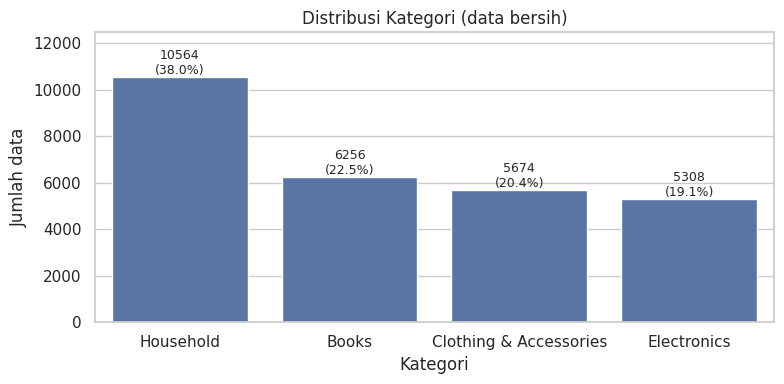

Rasio kelas terbesar : terkecil = 1.99 : 1


In [102]:
counts = df["label"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#4C72B0")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({v / counts.sum():.1%})", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi Kategori (data bersih)")
ax.set_xlabel("Kategori"); ax.set_ylabel("Jumlah data")
ax.set_ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_distribusi_kelas.png", dpi=150); plt.show()

rasio = counts.max() / counts.min()
print(f"Rasio kelas terbesar : terkecil = {rasio:.2f} : 1")

> Jika rasio kelas terbesar dan terkecil jauh dari 1, kelasnya **tidak seimbang**. Accuracy bisa terlihat tinggi hanya karena model bagus di kelas besar, sehingga **F1-macro** dipakai sebagai metrik utama: setiap kategori mendapat bobot yang sama.

### 3.2 Panjang teks (jumlah kata) per kategori

,rata_rata,median,min,maks
label,,,,
Books,140.0,73.0,1.0,8181.0
Clothing & Accessories,72.6,56.0,1.0,581.0
Electronics,130.5,97.0,1.0,1997.0
Household,107.0,84.0,1.0,1791.0


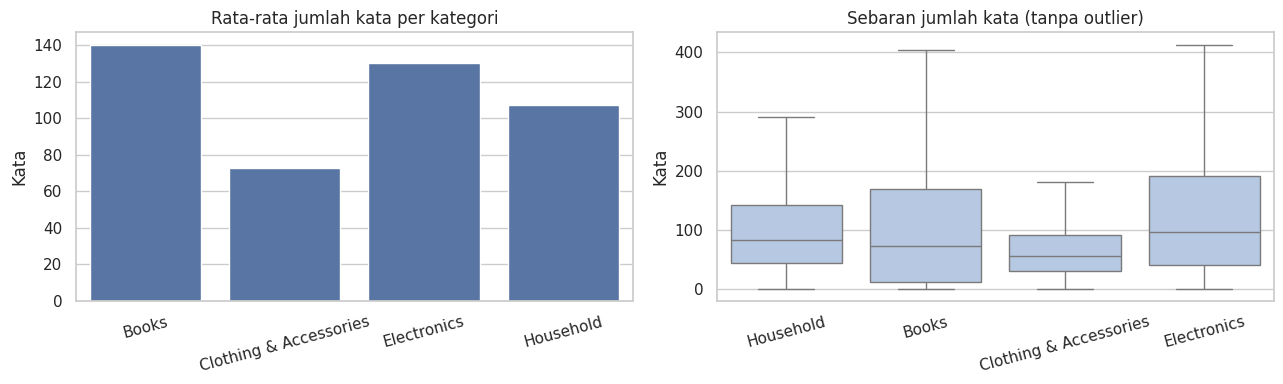

In [103]:
df["n_kata"] = df["text"].str.split().str.len()
stat_panjang = df.groupby("label")["n_kata"].describe()[["mean", "50%", "min", "max"]]
stat_panjang.columns = ["rata_rata", "median", "min", "maks"]
display(stat_panjang.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=stat_panjang.index, y=stat_panjang["rata_rata"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Rata-rata jumlah kata per kategori"); axes[0].set_xlabel(""); axes[0].set_ylabel("Kata")
sns.boxplot(data=df, x="label", y="n_kata", ax=axes[1], showfliers=False, color="#AFC6E9")
axes[1].set_title("Sebaran jumlah kata (tanpa outlier)"); axes[1].set_xlabel(""); axes[1].set_ylabel("Kata")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_panjang_teks.png", dpi=150); plt.show()

### 3.3 Kata paling sering per kategori

Untuk EDA, teks hanya di-lowercase dan diambil kata alfabetnya, lalu stopword bahasa Inggris dibuang supaya kata yang tampil bermakna.

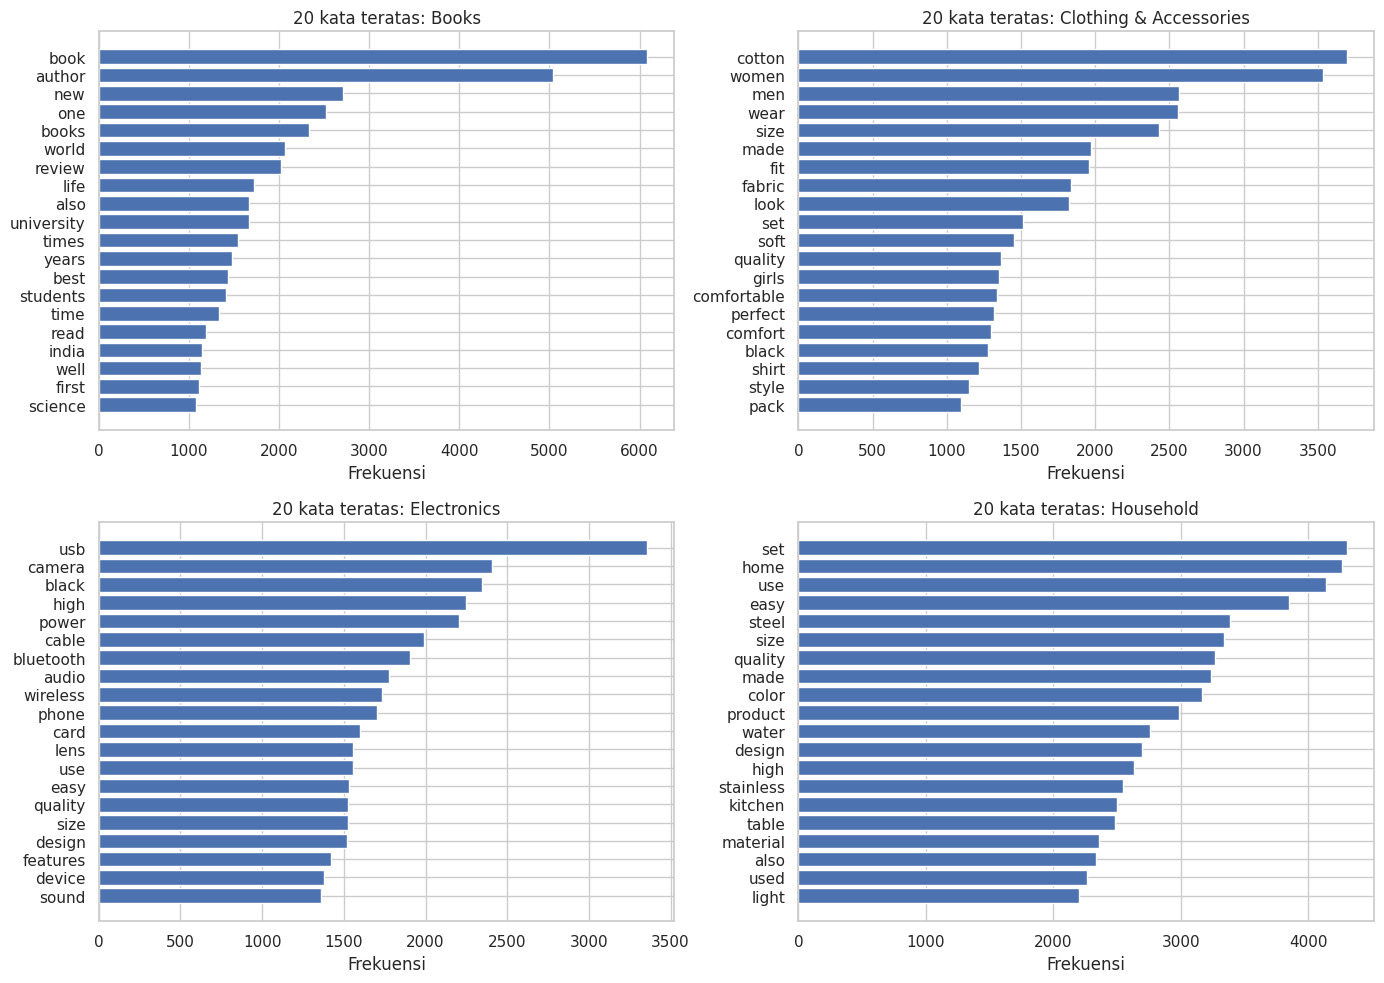

In [104]:
STOPWORDS = set(stopwords.words("english"))

def kata_teratas(teks_series, n=20):
    counter = Counter()
    for t in teks_series:
        counter.update(w for w in re.findall(r"[a-z]+", t.lower())
                       if w not in STOPWORDS and len(w) > 2)
    return counter.most_common(n)

kategori = sorted(df["label"].unique())
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, kat in zip(axes.ravel(), kategori):
    top = kata_teratas(df.loc[df["label"] == kat, "text"])
    kata, freq = zip(*top)
    ax.barh(kata[::-1], freq[::-1], color="#4C72B0")
    ax.set_title(f"20 kata teratas: {kat}")
    ax.set_xlabel("Frekuensi")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_kata_teratas.png", dpi=150); plt.show()

## Tahap 4. Preprocessing Teks

1. **Case folding**: semua huruf menjadi kecil.
2. **Cleaning**: hapus URL, angka, tanda baca, dan simbol.
3. **Tokenisasi**: pecah kalimat menjadi kata (berdasarkan spasi, karena tanda baca sudah dibuang).
4. **Stopword removal**: hapus stopword bahasa Inggris dan kata dengan panjang ≤ 2 huruf.
5. **Lemmatization**: WordNet lemmatizer (contoh: *books* → *book*).
6. Hapus data yang teksnya menjadi kosong.

Preprocessing boleh dilakukan sebelum pembagian data karena prosesnya per dokumen dan tidak memakai informasi dari dokumen lain.

In [105]:
lemmatizer = WordNetLemmatizer()
RE_URL = re.compile(r"(https?://\S+|www\.\S+)")
RE_NON_HURUF = re.compile(r"[^a-z\s]")      # angka, tanda baca, simbol

@lru_cache(maxsize=None)
def lemma(word):
    return lemmatizer.lemmatize(word)

def preprocess(text):
    text = text.lower()                                   # 1. case folding
    text = RE_URL.sub(" ", text)                          # 2. hapus URL
    text = RE_NON_HURUF.sub(" ", text)                    #    hapus angka/tanda baca/simbol
    tokens = text.split()                                 # 3. tokenisasi
    tokens = [w for w in tokens
              if w not in STOPWORDS and len(w) > 2]       # 4. stopword & kata pendek
    tokens = [lemma(w) for w in tokens]                   # 5. lemmatization
    return " ".join(tokens)

contoh = df["text"].iloc[0]
print("SEBELUM:", contoh[:300])
print("SESUDAH:", preprocess(contoh)[:300])

SEBELUM: Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. This is an special series of paintings which makes your wall very beautiful and gives 
SESUDAH: paper plane design framed wall hanging motivational office decor art print inch set painting made synthetic frame textured print give multi effect attracts towards special series painting make wall beautiful give royal touch painting ready hang would proud possess unique painting niche apart use mod


In [106]:
def preprocess_df(data):
    data = data.copy()
    data["clean"] = data["text"].map(preprocess)
    n_sebelum = len(data)
    data = data[data["clean"].str.len() > 0].reset_index(drop=True)
    return data, n_sebelum - len(data)

t0 = time.time()
df, n_kosong = preprocess_df(df)
print(f"Preprocessing selesai dalam {time.time() - t0:.1f} detik")
print("Data yang kosong setelah preprocessing dan dihapus:", n_kosong)
print("Jumlah data akhir:", len(df))
log_cleaning["Setelah preprocessing (hapus teks kosong)"] = len(df)
df[["label", "text", "clean"]].head()

Preprocessing selesai dalam 3.5 detik
Data yang kosong setelah preprocessing dan dihapus: 0
Jumlah data akhir: 27802


,label,text,clean
0,Household,Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and att...,paper plane design framed wall hanging motivational office decor art print inch set painting made synthetic frame textured print give multi effect attracts towards special series painting make wal...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Painting made up in synthetic frame with UV textured print which gives multi effects and attracts t...",saf floral framed painting wood inch inch special effect print textured sao painting made synthetic frame textured print give multi effect attracts towards special series painting make wall beauti...
2,Household,"SAF 'UV Textured Modern Art Print Framed' Painting (Synthetic, 35 cm x 50 cm x 3 cm, Set of 3) Color:Multicolor | ...",saf textured modern art print framed painting synthetic set color multicolor size overview beautiful painting involves action skill using paint right manner hence end product picture speak thousan...
3,Household,"SAF Flower Print Framed Painting (Synthetic, 13.5 inch x 22 inch, UV Textured, Set of 3, SANFSW4951) Color:Multicolor ...",saf flower print framed painting synthetic inch inch textured set sanfsw color multicolor size beautiful painting involves action skill using paint right manner hence end product picture speak tho...
4,Household,"Incredible Gifts India Wooden Happy Birthday Unique Personalized Gift (5 X 4 Inch) Size:4 x 5 Made Of Natural Imported Wood, Which Is Quite Solid With Light Particle Pattern & Is Soft Pale To Bl...",incredible gift india wooden happy birthday unique personalized gift inch size made natural imported wood quite solid light particle pattern soft pale blond colour uploaded photo look amazing beau...


## Tahap 5. Pembagian Data

Stratified split 80:20 dengan `random_state = 42`. Data uji disimpan dan **tidak disentuh** sampai evaluasi akhir; semua tuning hanya memakai data latih.

In [107]:
def split_data(data):
    return train_test_split(data["clean"], data["label"], test_size=0.20,
                            stratify=data["label"], random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = split_data(df)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

pd.DataFrame({
    "latih": y_train.value_counts(normalize=True).round(4),
    "uji": y_test.value_counts(normalize=True).round(4),
})

Data latih: 22241 | Data uji: 5561


,latih,uji
label,,
Household,0.3800,0.3800
Books,0.2250,0.2250
Clothing & Accessories,0.2041,0.2041
Electronics,0.1909,0.1910


## Tahap 6. Ekstraksi Fitur (TF-IDF)

Pengaturan TF-IDF yang **sama** untuk keempat model:

| Parameter | Nilai | Arti |
|---|---|---|
| `ngram_range` | (1, 2) | unigram + bigram |
| `max_features` | 20.000 | hanya 20.000 kata/frasa terpenting |
| `min_df` | 2 | kata yang hanya muncul di satu dokumen diabaikan |
| `sublinear_tf` | True | TF diskalakan logaritmik: 1 + log(tf) |

TF-IDF digabung dengan algoritma dalam satu `Pipeline`, sehingga di setiap fold cross validation TF-IDF dihitung ulang **hanya dari data latih fold tersebut**. Ini mencegah kebocoran informasi dari data validasi/uji.

In [108]:
def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), max_features=20000,
                           min_df=2, sublinear_tf=True)

# Gambaran ukuran ruang fitur (hanya untuk informasi; fit di data latih saja)
_tfidf_demo = make_tfidf().fit(X_train)
_Xtr_demo = _tfidf_demo.transform(X_train)
print("Ukuran matriks TF-IDF data latih:", _Xtr_demo.shape)
print(f"Sparsity: {1 - _Xtr_demo.nnz / np.prod(_Xtr_demo.shape):.4%} elemen bernilai nol")
del _tfidf_demo, _Xtr_demo

Ukuran matriks TF-IDF data latih: (22241, 20000)
Sparsity: 99.7067% elemen bernilai nol


## Tahap 7. Modeling: Training dan Tuning

Keempat algoritma dilatih terpisah dengan data latih dan fitur yang sama. Untuk setiap algoritma ada dua langkah (cell terpisah):

1. **Training**: model dilatih dengan hyperparameter *default* di seluruh data latih (sebagai pembanding sebelum tuning).
2. **Tuning**: hyperparameter dicari dengan **Grid Search + stratified CV** memakai **F1-macro**, lalu model dilatih ulang dengan parameter terbaik di seluruh data latih. Model hasil tuning inilah yang dipakai pada tahap evaluasi.

| Model | Peran | Hyperparameter | CV |
|---|---|---|---|
| ANN (MLPClassifier, 1 hidden layer 128 neuron) | model neural network | `alpha` ∈ {0,0001; 0,001} | 3-fold |
| Multinomial Naive Bayes | baseline | `alpha` ∈ {0,01; 0,1; 0,5; 1,0} | 5-fold |
| LinearSVC (one-vs-rest) | model utama | `C` ∈ {0,01; 0,1; 1; 10} | 5-fold |
| Random Forest | model non-linear + feature importance | `n_estimators` ∈ {100; 300}, `max_depth` ∈ {None; 50} | 5-fold |

> Catatan: ANN dan Random Forest pada 20.000 fitur adalah tahap paling lama (bisa beberapa menit sampai puluhan menit, tergantung CPU). Karena itu ANN memakai 3-fold CV.

In [109]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import ParameterGrid

hasil = {}           # model hasil tuning tiap algoritma (dipakai di tahap evaluasi)
hasil_default = {}   # model dengan hyperparameter default (sebelum tuning)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)   # khusus ANN

PARAM_GRIDS = {
    "ANN": {"clf__alpha": [1e-4, 1e-3]},
    "Naive Bayes": {"clf__alpha": [0.01, 0.1, 0.5, 1.0]},
    "SVM": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 50]},
}

def train_default(name, pipe, X_tr, y_tr, X_te, y_te, decode=None):
    # Training dengan hyperparameter default di seluruh data latih -> prediksi data uji
    model = clone(pipe)
    t0 = time.time(); model.fit(X_tr, y_tr); waktu_train = time.time() - t0
    t0 = time.time(); y_pred = model.predict(X_te); waktu_pred = time.time() - t0
    if decode is not None:
        y_pred = decode(y_pred)

    hasil_default[name] = {"model": model, "y_pred": y_pred,
                           "waktu_train_s": waktu_train, "waktu_prediksi_s": waktu_pred}
    print(f"{name:14s} | default | F1-macro uji = {f1_score(y_te, y_pred, average='macro'):.4f} "
          f"| train {waktu_train:.2f}s | prediksi {waktu_pred:.3f}s")
    return model

def train_best(name, pipe, best_params, cv_score, cv_results, waktu_tuning, X_tr, y_tr, X_te, decode=None):
    # Latih ulang dengan parameter terbaik di seluruh data latih -> prediksi data uji
    best_model = clone(pipe).set_params(**best_params)
    t0 = time.time(); best_model.fit(X_tr, y_tr); waktu_train = time.time() - t0
    t0 = time.time(); y_pred = best_model.predict(X_te); waktu_pred = time.time() - t0
    if decode is not None:
        y_pred = decode(y_pred)

    hasil[name] = {
        "model": best_model, "y_pred": y_pred,
        "best_params": {k.replace("clf__", ""): v for k, v in best_params.items()},
        "cv_f1_macro": cv_score,
        "cv_results": cv_results,
        "waktu_tuning_s": waktu_tuning, "waktu_train_s": waktu_train, "waktu_prediksi_s": waktu_pred,
    }
    print(f"{name:14s} | best {hasil[name]['best_params']} | CV F1-macro = {cv_score:.4f} "
          f"| tuning {waktu_tuning:.1f}s | train {waktu_train:.2f}s | prediksi {waktu_pred:.3f}s")
    return best_model

def tune_grid(name, pipe, X_tr, y_tr, X_te):
    # Grid search 5-fold (tanpa refit) -> latih ulang dengan parameter terbaik
    t0 = time.time()
    gs = GridSearchCV(pipe, PARAM_GRIDS[name], scoring="f1_macro",
                      cv=cv5, n_jobs=N_JOBS, refit=False)
    gs.fit(X_tr, y_tr)
    waktu_tuning = time.time() - t0
    return train_best(name, pipe, gs.best_params_, gs.best_score_,
                      pd.DataFrame(gs.cv_results_), waktu_tuning, X_tr, y_tr, X_te)

def tampilkan_default(name, y_te):
    # Ringkasan hasil training dengan hyperparameter default
    r = hasil_default[name]
    yp = r["y_pred"]
    print(f"\n===== {name}: hasil training (hyperparameter default) =====")
    print(f"Accuracy          : {accuracy_score(y_te, yp):.4f}")
    print(f"Precision (macro) : {precision_score(y_te, yp, average='macro'):.4f}")
    print(f"Recall (macro)    : {recall_score(y_te, yp, average='macro'):.4f}")
    print(f"F1-macro          : {f1_score(y_te, yp, average='macro'):.4f}")
    print(f"Waktu training    : {r['waktu_train_s']:.2f} s | waktu prediksi: {r['waktu_prediksi_s']:.3f} s\n")
    print(classification_report(y_te, yp, digits=4))

def tampilkan_tuning(name, y_te):
    # Ringkasan hasil grid search + performa model terbaik di data uji
    r = hasil[name]
    yp = r["y_pred"]
    f1_def = f1_score(y_te, hasil_default[name]["y_pred"], average="macro") if name in hasil_default else np.nan
    f1_tun = f1_score(y_te, yp, average="macro")
    print(f"\n===== {name}: hasil tuning =====")
    print("Hasil grid search (diurutkan dari skor CV terbaik):")
    display(r["cv_results"][["params", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score").round(4))
    print(f"Hyperparameter terbaik : {r['best_params']}")
    print(f"CV F1-macro terbaik    : {r['cv_f1_macro']:.4f}")
    print(f"Waktu tuning           : {r['waktu_tuning_s']:.1f} s | training ulang: {r['waktu_train_s']:.2f} s")
    print(f"Accuracy uji           : {accuracy_score(y_te, yp):.4f}")
    print(f"F1-macro uji           : default {f1_def:.4f} -> setelah tuning {f1_tun:.4f} "
          f"(selisih {f1_tun - f1_def:+.4f})\n")
    print(classification_report(y_te, yp, digits=4))

### 7.1 Artificial Neural Network (MLPClassifier)

Arsitektur: input TF-IDF → 1 hidden layer 128 neuron (ReLU) → output softmax 4 kelas, optimizer Adam, maksimal 30 epoch dengan *early stopping* (10% data latih sebagai validasi, berhenti jika 3 epoch tidak membaik).

In [110]:
# ===== Training ANN (hyperparameter default: alpha = 0.0001) =====
# MLPClassifier + early_stopping error jika label berupa teks (bug scikit-learn: np.isnan pada prediksi string),
# jadi khusus ANN label diubah ke angka dan prediksinya dikembalikan ke nama kategori.
le_ann = LabelEncoder().fit(y_train)
y_train_enc = le_ann.transform(y_train)

SHOW_EPOCH = True   # True: tampilkan loss & skor validasi tiap epoch | False: hanya progres per fold

pipe_ann = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", MLPClassifier(hidden_layer_sizes=(128,), activation="relu", solver="adam",
                          max_iter=30, early_stopping=True, validation_fraction=0.1,
                          n_iter_no_change=3, random_state=RANDOM_STATE,
                          verbose=SHOW_EPOCH)),
])

ann_default = train_default("ANN", pipe_ann, X_train, y_train_enc, X_test, y_test,
                            decode=le_ann.inverse_transform)
print("Jumlah epoch:", ann_default.named_steps["clf"].n_iter_)

Iteration 1, loss = 0.68990916
Validation score: 0.954157
Iteration 2, loss = 0.19184662
Validation score: 0.959101
Iteration 3, loss = 0.11341824
Validation score: 0.962697
Iteration 4, loss = 0.07233103
Validation score: 0.962697
Iteration 5, loss = 0.04811713
Validation score: 0.960449
Iteration 6, loss = 0.03347673
Validation score: 0.960899
Iteration 7, loss = 0.02490105
Validation score: 0.962247
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
ANN            | default | F1-macro uji = 0.9572 | train 80.88s | prediksi 1.417s
Jumlah epoch: 7


In [111]:
# ===== Tuning ANN: grid search manual 3-fold dengan progress =====
X_tr = pd.Series(X_train).reset_index(drop=True)
y_tr = np.asarray(y_train_enc)

grid  = list(ParameterGrid(PARAM_GRIDS["ANN"]))
folds = list(cv3.split(X_tr, y_tr))
total = len(grid) * len(folds)
print(f"Tuning ANN: {len(grid)} kombinasi x {len(folds)} fold = {total} training\n")

rows, done = [], 0
t0 = time.time()
for params in grid:
    p_label = {k.replace("clf__", ""): v for k, v in params.items()}
    scores, epochs = [], []

    for k, (tr_idx, va_idx) in enumerate(folds, 1):
        print(f"--- [{done + 1}/{total}] {p_label} | fold {k}/{len(folds)} mulai ---", flush=True)
        t_fit = time.time()

        model = clone(pipe_ann).set_params(**params)
        model.fit(X_tr.iloc[tr_idx], y_tr[tr_idx])
        f1 = f1_score(y_tr[va_idx], model.predict(X_tr.iloc[va_idx]), average="macro")

        scores.append(f1)
        epochs.append(model.named_steps["clf"].n_iter_)
        done += 1

        elapsed = time.time() - t0
        eta = elapsed / done * (total - done)
        print(f"[{done}/{total}] selesai | F1-macro = {f1:.4f} | epoch = {epochs[-1]} "
              f"| durasi {time.time() - t_fit:.0f} dtk | berjalan {elapsed/60:.1f} mnt "
              f"| sisa ±{eta/60:.1f} mnt\n", flush=True)

    rows.append({"params": params,
                 "mean_test_score": np.mean(scores), "std_test_score": np.std(scores),
                 "mean_epoch": np.mean(epochs),
                 **{f"split{i}_test_score": s for i, s in enumerate(scores)}})

waktu_tuning = time.time() - t0
cv_results_ann = pd.DataFrame(rows)
cv_results_ann["rank_test_score"] = (cv_results_ann["mean_test_score"]
                                     .rank(ascending=False, method="min").astype(int))
best_row = cv_results_ann.loc[cv_results_ann["mean_test_score"].idxmax()]
print(f"Tuning selesai dalam {waktu_tuning/60:.1f} menit | best {best_row['params']} "
      f"| CV F1 = {best_row['mean_test_score']:.4f}\n")

# Training akhir dengan parameter terbaik di seluruh data latih
print("Training model akhir di seluruh data latih ...", flush=True)
ann_model = train_best("ANN", pipe_ann, best_row["params"], best_row["mean_test_score"],
                       cv_results_ann, waktu_tuning, X_train, y_train_enc, X_test,
                       decode=le_ann.inverse_transform)
print("Jumlah epoch:", ann_model.named_steps["clf"].n_iter_)

Tuning ANN: 2 kombinasi x 3 fold = 6 training

--- [1/6] {'alpha': 0.0001} | fold 1/3 mulai ---
Iteration 1, loss = 0.86477854
Validation score: 0.943358
Iteration 2, loss = 0.26016210
Validation score: 0.952798
Iteration 3, loss = 0.14357731
Validation score: 0.956170
Iteration 4, loss = 0.09214904
Validation score: 0.959541
Iteration 5, loss = 0.06091804
Validation score: 0.958867
Iteration 6, loss = 0.04169524
Validation score: 0.958867
Iteration 7, loss = 0.03001602
Validation score: 0.959541
Iteration 8, loss = 0.02212992
Validation score: 0.958867
Validation score did not improve more than tol=0.000100 for 3 consecutive epochs. Stopping.
[1/6] selesai | F1-macro = 0.9503 | epoch = 8 | durasi 54 dtk | berjalan 0.9 mnt | sisa ±4.5 mnt

--- [2/6] {'alpha': 0.0001} | fold 2/3 mulai ---
Iteration 1, loss = 0.87181552
Validation score: 0.927849
Iteration 2, loss = 0.26365220
Validation score: 0.939987
Iteration 3, loss = 0.14438136
Validation score: 0.947404
Iteration 4, loss = 0.09321

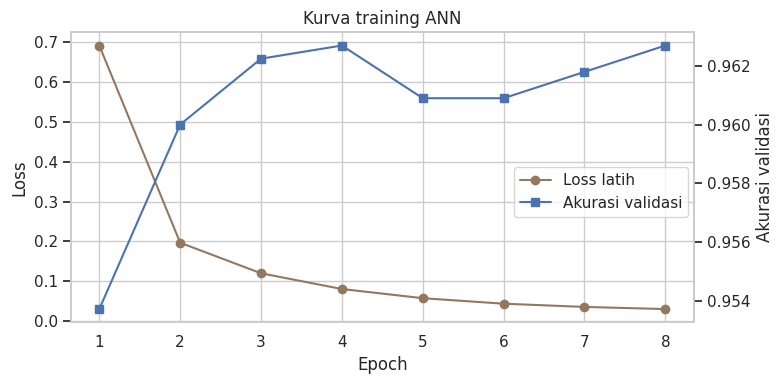

In [112]:
# Kurva training ANN (model final): loss latih dan skor validasi internal per epoch
mlp = ann_model.named_steps["clf"]
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, marker="o", color=MODEL_COLORS["ANN"], label="Loss latih")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax2 = ax1.twinx()
ax2.plot(range(1, len(mlp.validation_scores_) + 1), mlp.validation_scores_, marker="s", color="#4C72B0", label="Akurasi validasi")
ax2.set_ylabel("Akurasi validasi"); ax2.grid(False)
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
ax1.set_title("Kurva training ANN")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ann_kurva_training.png", dpi=150); plt.show()

### 7.2 Multinomial Naive Bayes

In [113]:
# ===== Training Naive Bayes (hyperparameter default: alpha = 1.0) =====
pipe_nb = Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB())])
nb_default = train_default("Naive Bayes", pipe_nb, X_train, y_train, X_test, y_test)
tampilkan_default("Naive Bayes", y_test)

Naive Bayes    | default | F1-macro uji = 0.9398 | train 7.21s | prediksi 1.214s

===== Naive Bayes: hasil training (hyperparameter default) =====
Accuracy          : 0.9394
Precision (macro) : 0.9449
Recall (macro)    : 0.9356
F1-macro          : 0.9398
Waktu training    : 7.21 s | waktu prediksi: 1.214 s

                        precision    recall  f1-score   support

                 Books     0.9706    0.8977    0.9327      1251
Clothing & Accessories     0.9623    0.9674    0.9649      1135
           Electronics     0.9321    0.9171    0.9245      1062
             Household     0.9148    0.9602    0.9370      2113

              accuracy                         0.9394      5561
             macro avg     0.9449    0.9356    0.9398      5561
          weighted avg     0.9403    0.9394    0.9393      5561



In [114]:
# ===== Tuning Naive Bayes (Grid Search 5-fold) =====
nb_model = tune_grid("Naive Bayes", pipe_nb, X_train, y_train, X_test)
tampilkan_tuning("Naive Bayes", y_test)

Naive Bayes    | best {'alpha': 0.01} | CV F1-macro = 0.9441 | tuning 130.2s | train 9.22s | prediksi 0.699s

===== Naive Bayes: hasil tuning =====
Hasil grid search (diurutkan dari skor CV terbaik):


,params,mean_test_score,std_test_score,rank_test_score
0,{'clf__alpha': 0.01},0.9441,0.0036,1
1,{'clf__alpha': 0.1},0.9438,0.0029,2
2,{'clf__alpha': 0.5},0.9413,0.0035,3
3,{'clf__alpha': 1.0},0.9382,0.0032,4


Hyperparameter terbaik : {'alpha': 0.01}
CV F1-macro terbaik    : 0.9441
Waktu tuning           : 130.2 s | training ulang: 9.22 s
Accuracy uji           : 0.9439
F1-macro uji           : default 0.9398 -> setelah tuning 0.9440 (selisih +0.0042)

                        precision    recall  f1-score   support

                 Books     0.9684    0.9065    0.9364      1251
Clothing & Accessories     0.9652    0.9771    0.9711      1135
           Electronics     0.9216    0.9303    0.9260      1062
             Household     0.9304    0.9550    0.9426      2113

              accuracy                         0.9439      5561
             macro avg     0.9464    0.9422    0.9440      5561
          weighted avg     0.9444    0.9439    0.9438      5561



### 7.3 Linear SVM (LinearSVC)

In [115]:
# ===== Training SVM (hyperparameter default: C = 1.0) =====
pipe_svm = Pipeline([("tfidf", make_tfidf()),
                     ("clf", LinearSVC(random_state=RANDOM_STATE, max_iter=10000))])
svm_default = train_default("SVM", pipe_svm, X_train, y_train, X_test, y_test)
tampilkan_default("SVM", y_test)

SVM            | default | F1-macro uji = 0.9601 | train 10.54s | prediksi 0.793s

===== SVM: hasil training (hyperparameter default) =====
Accuracy          : 0.9603
Precision (macro) : 0.9623
Recall (macro)    : 0.9580
F1-macro          : 0.9601
Waktu training    : 10.54 s | waktu prediksi: 0.793 s

                        precision    recall  f1-score   support

                 Books     0.9653    0.9345    0.9496      1251
Clothing & Accessories     0.9806    0.9815    0.9811      1135
           Electronics     0.9534    0.9435    0.9484      1062
             Household     0.9501    0.9726    0.9612      2113

              accuracy                         0.9603      5561
             macro avg     0.9623    0.9580    0.9601      5561
          weighted avg     0.9604    0.9603    0.9602      5561



In [116]:
# ===== Tuning SVM (Grid Search 5-fold) =====
svm_model = tune_grid("SVM", pipe_svm, X_train, y_train, X_test)
tampilkan_tuning("SVM", y_test)

SVM            | best {'C': 1} | CV F1-macro = 0.9566 | tuning 142.6s | train 10.90s | prediksi 0.753s

===== SVM: hasil tuning =====
Hasil grid search (diurutkan dari skor CV terbaik):


,params,mean_test_score,std_test_score,rank_test_score
2,{'clf__C': 1},0.9566,0.0032,1
3,{'clf__C': 10},0.9539,0.0019,2
1,{'clf__C': 0.1},0.9488,0.0037,3
0,{'clf__C': 0.01},0.9217,0.0025,4


Hyperparameter terbaik : {'C': 1}
CV F1-macro terbaik    : 0.9566
Waktu tuning           : 142.6 s | training ulang: 10.90 s
Accuracy uji           : 0.9603
F1-macro uji           : default 0.9601 -> setelah tuning 0.9601 (selisih +0.0000)

                        precision    recall  f1-score   support

                 Books     0.9653    0.9345    0.9496      1251
Clothing & Accessories     0.9806    0.9815    0.9811      1135
           Electronics     0.9534    0.9435    0.9484      1062
             Household     0.9501    0.9726    0.9612      2113

              accuracy                         0.9603      5561
             macro avg     0.9623    0.9580    0.9601      5561
          weighted avg     0.9604    0.9603    0.9602      5561



### 7.4 Random Forest

In [117]:
# ===== Training Random Forest (hyperparameter default: n_estimators = 100, max_depth = None) =====
pipe_rf = Pipeline([("tfidf", make_tfidf()),
                    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))])
rf_default = train_default("Random Forest", pipe_rf, X_train, y_train, X_test, y_test)
tampilkan_default("Random Forest", y_test)

Random Forest  | default | F1-macro uji = 0.9312 | train 55.55s | prediksi 1.766s

===== Random Forest: hasil training (hyperparameter default) =====
Accuracy          : 0.9311
Precision (macro) : 0.9363
Recall (macro)    : 0.9269
F1-macro          : 0.9312
Waktu training    : 55.55 s | waktu prediksi: 1.766 s

                        precision    recall  f1-score   support

                 Books     0.9384    0.9137    0.9259      1251
Clothing & Accessories     0.9596    0.9621    0.9608      1135
           Electronics     0.9379    0.8823    0.9093      1062
             Household     0.9093    0.9494    0.9289      2113

              accuracy                         0.9311      5561
             macro avg     0.9363    0.9269    0.9312      5561
          weighted avg     0.9316    0.9311    0.9310      5561



In [118]:
# ===== Tuning Random Forest (Grid Search 5-fold) =====
rf_model = tune_grid("Random Forest", pipe_rf, X_train, y_train, X_test)
tampilkan_tuning("Random Forest", y_test)

Random Forest  | best {'max_depth': None, 'n_estimators': 300} | CV F1-macro = 0.9292 | tuning 992.9s | train 156.58s | prediksi 1.842s

===== Random Forest: hasil tuning =====
Hasil grid search (diurutkan dari skor CV terbaik):


,params,mean_test_score,std_test_score,rank_test_score
1,"{'clf__max_depth': None, 'clf__n_estimators': 300}",0.9292,0.0032,1
0,"{'clf__max_depth': None, 'clf__n_estimators': 100}",0.9281,0.0025,2
3,"{'clf__max_depth': 50, 'clf__n_estimators': 300}",0.9177,0.0022,3
2,"{'clf__max_depth': 50, 'clf__n_estimators': 100}",0.9149,0.0023,4


Hyperparameter terbaik : {'max_depth': None, 'n_estimators': 300}
CV F1-macro terbaik    : 0.9292
Waktu tuning           : 992.9 s | training ulang: 156.58 s
Accuracy uji           : 0.9324
F1-macro uji           : default 0.9312 -> setelah tuning 0.9322 (selisih +0.0009)

                        precision    recall  f1-score   support

                 Books     0.9386    0.9161    0.9272      1251
Clothing & Accessories     0.9572    0.9656    0.9614      1135
           Electronics     0.9460    0.8748    0.9090      1062
             Household     0.9101    0.9531    0.9311      2113

              accuracy                         0.9324      5561
             macro avg     0.9380    0.9274    0.9322      5561
          weighted avg     0.9330    0.9324    0.9322      5561



### 7.5 Ringkasan hasil training dan tuning

In [119]:
# F1-macro data uji sebelum (default) vs sesudah tuning
pd.DataFrame({
    name: {
        "F1-macro default": f1_score(y_test, hasil_default[name]["y_pred"], average="macro"),
        "F1-macro setelah tuning": f1_score(y_test, hasil[name]["y_pred"], average="macro"),
    } for name in MODEL_NAMES
}).T.assign(selisih=lambda d: d["F1-macro setelah tuning"] - d["F1-macro default"]).round(4)

,F1-macro default,F1-macro setelah tuning,selisih
ANN,0.9572,0.9580,0.0008
Naive Bayes,0.9398,0.9440,0.0042
SVM,0.9601,0.9601,0.0000
Random Forest,0.9312,0.9322,0.0009


In [120]:
# Hasil grid search lengkap per model
for name in MODEL_NAMES:
    cvr = hasil[name]["cv_results"]
    print(f"\n=== {name} ===")
    display(cvr[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score").round(4))


=== ANN ===


,params,mean_test_score,std_test_score,rank_test_score
1,{'clf__alpha': 0.001},0.9536,0.0024,1
0,{'clf__alpha': 0.0001},0.9534,0.0023,2



=== Naive Bayes ===


,params,mean_test_score,std_test_score,rank_test_score
0,{'clf__alpha': 0.01},0.9441,0.0036,1
1,{'clf__alpha': 0.1},0.9438,0.0029,2
2,{'clf__alpha': 0.5},0.9413,0.0035,3
3,{'clf__alpha': 1.0},0.9382,0.0032,4



=== SVM ===


,params,mean_test_score,std_test_score,rank_test_score
2,{'clf__C': 1},0.9566,0.0032,1
3,{'clf__C': 10},0.9539,0.0019,2
1,{'clf__C': 0.1},0.9488,0.0037,3
0,{'clf__C': 0.01},0.9217,0.0025,4



=== Random Forest ===


,params,mean_test_score,std_test_score,rank_test_score
1,"{'clf__max_depth': None, 'clf__n_estimators': 300}",0.9292,0.0032,1
0,"{'clf__max_depth': None, 'clf__n_estimators': 100}",0.9281,0.0025,2
3,"{'clf__max_depth': 50, 'clf__n_estimators': 300}",0.9177,0.0022,3
2,"{'clf__max_depth': 50, 'clf__n_estimators': 100}",0.9149,0.0023,4


In [121]:
tabel_tuning = pd.DataFrame({
    name: {
        "Hyperparameter terbaik": hasil[name]["best_params"],
        "CV F1-macro": round(hasil[name]["cv_f1_macro"], 4),
        "Waktu tuning (s)": round(hasil[name]["waktu_tuning_s"], 2),
        "Waktu training (s)": round(hasil[name]["waktu_train_s"], 3),
        "Waktu prediksi (s)": round(hasil[name]["waktu_prediksi_s"], 4),
    } for name in MODEL_NAMES
}).T
tabel_tuning

,Hyperparameter terbaik,CV F1-macro,Waktu tuning (s),Waktu training (s),Waktu prediksi (s)
ANN,{'alpha': 0.001},0.9536,329.5,78.279,0.8216
Naive Bayes,{'alpha': 0.01},0.9441,130.25,9.215,0.6993
SVM,{'C': 1},0.9566,142.56,10.895,0.7528
Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.9292,992.87,156.583,1.8419


## Tahap 8. Evaluasi dan Perbandingan

Semua model dievaluasi pada data uji yang sama. Precision dan recall dilaporkan dalam rata-rata *macro* (setiap kategori berbobot sama), konsisten dengan F1-macro.

In [122]:
def evaluasi(hasil, y_true):
    baris = {}
    for name in MODEL_NAMES:
        yp = hasil[name]["y_pred"]
        baris[name] = {
            "Accuracy": accuracy_score(y_true, yp),
            "Precision (macro)": precision_score(y_true, yp, average="macro"),
            "Recall (macro)": recall_score(y_true, yp, average="macro"),
            "F1-macro": f1_score(y_true, yp, average="macro"),
            "Waktu training (s)": hasil[name]["waktu_train_s"],
            "Waktu prediksi (s)": hasil[name]["waktu_prediksi_s"],
        }
    return pd.DataFrame(baris).T

tabel_eval = evaluasi(hasil, y_test)
tabel_eval.to_csv(f"{FIG_DIR}/tabel_perbandingan.csv")
tabel_eval.round(4)

,Accuracy,Precision (macro),Recall (macro),F1-macro,Waktu training (s),Waktu prediksi (s)
ANN,0.9581,0.9607,0.9556,0.9580,78.2786,0.8216
Naive Bayes,0.9439,0.9464,0.9422,0.9440,9.2150,0.6993
SVM,0.9603,0.9623,0.9580,0.9601,10.8950,0.7528
Random Forest,0.9324,0.9380,0.9274,0.9322,156.5833,1.8419


In [123]:
for name in MODEL_NAMES:
    print(f"=== {name} ===")
    print(classification_report(y_test, hasil[name]["y_pred"], digits=4))

=== ANN ===
                        precision    recall  f1-score   support

                 Books     0.9622    0.9361    0.9489      1251
Clothing & Accessories     0.9841    0.9789    0.9814      1135
           Electronics     0.9503    0.9369    0.9436      1062
             Household     0.9460    0.9707    0.9582      2113

              accuracy                         0.9581      5561
             macro avg     0.9607    0.9556    0.9580      5561
          weighted avg     0.9583    0.9581    0.9581      5561

=== Naive Bayes ===
                        precision    recall  f1-score   support

                 Books     0.9684    0.9065    0.9364      1251
Clothing & Accessories     0.9652    0.9771    0.9711      1135
           Electronics     0.9216    0.9303    0.9260      1062
             Household     0.9304    0.9550    0.9426      2113

              accuracy                         0.9439      5561
             macro avg     0.9464    0.9422    0.9440      5561
   

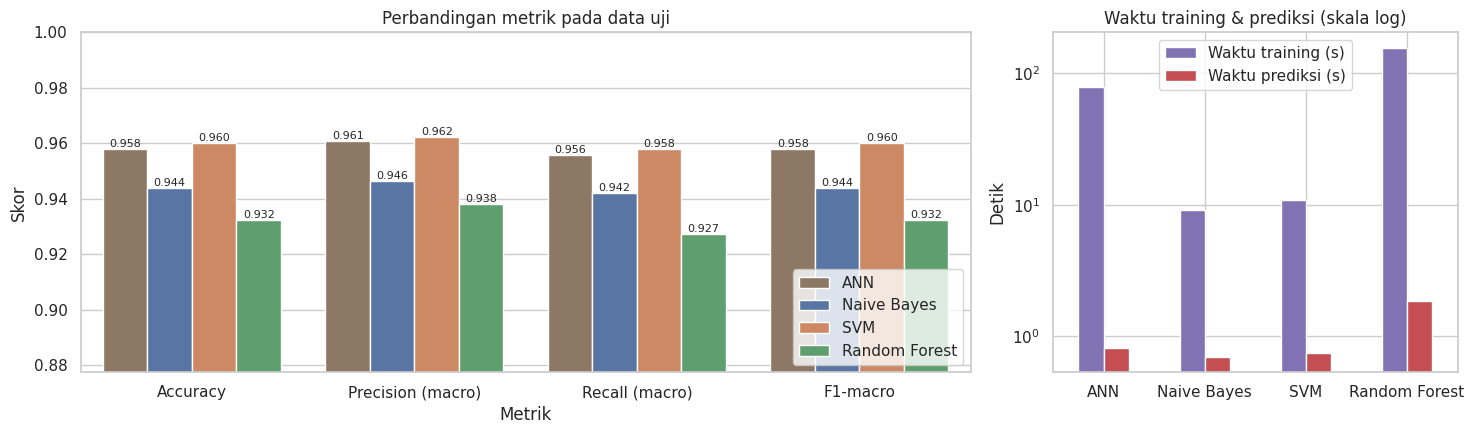

In [124]:
metrik = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-macro"]
plot_df = tabel_eval[metrik].reset_index().melt(id_vars="index", var_name="Metrik", value_name="Skor")
plot_df = plot_df.rename(columns={"index": "Model"})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
sns.barplot(data=plot_df, x="Metrik", y="Skor", hue="Model", palette=MODEL_COLORS, ax=axes[0])
lo = plot_df["Skor"].min()
axes[0].set_ylim(max(0, lo - 0.05), 1.0)
axes[0].set_title("Perbandingan metrik pada data uji")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=8)
axes[0].legend(loc="lower right")

waktu = tabel_eval[["Waktu training (s)", "Waktu prediksi (s)"]]
waktu.plot(kind="bar", ax=axes[1], logy=True, color=["#8172B3", "#C44E52"])
axes[1].set_title("Waktu training & prediksi (skala log)")
axes[1].set_ylabel("Detik"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/perbandingan_metrik.png", dpi=150); plt.show()

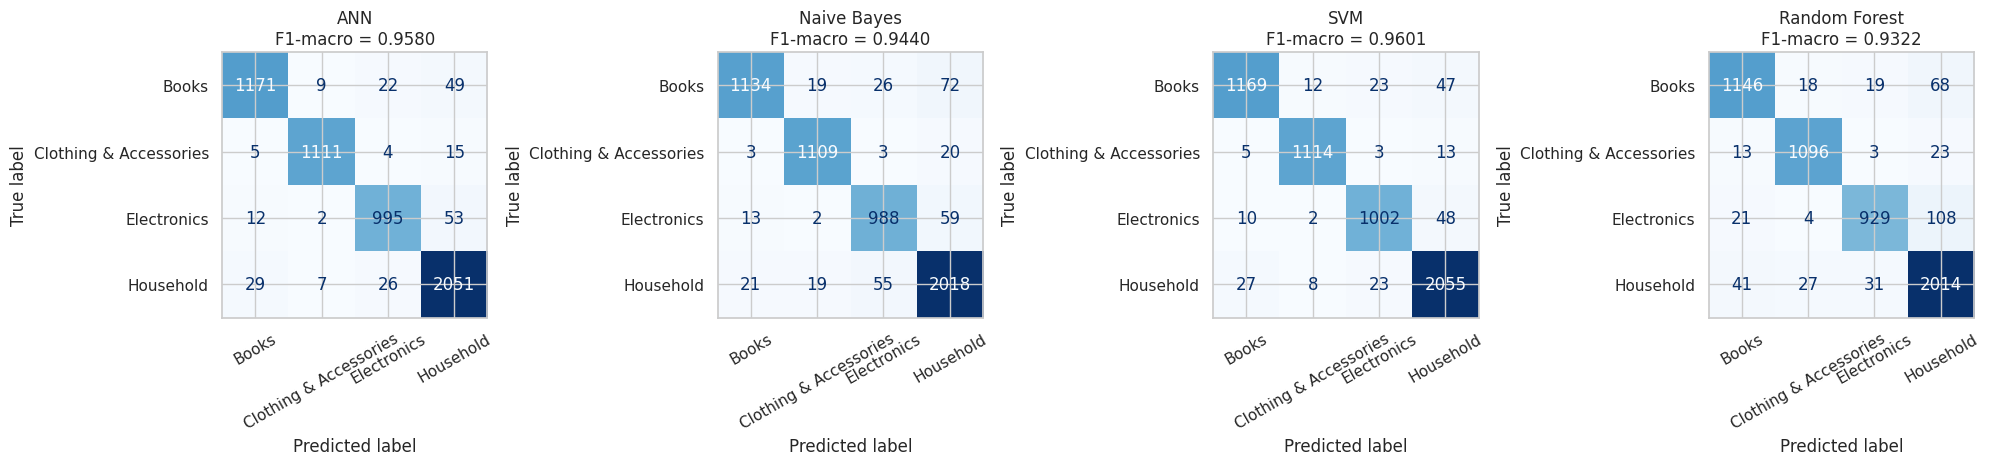

In [125]:
labels_urut = sorted(y_test.unique())
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(5 * len(MODEL_NAMES), 5.5))
for ax, name in zip(axes, MODEL_NAMES):
    cm = confusion_matrix(y_test, hasil[name]["y_pred"], labels=labels_urut)
    ConfusionMatrixDisplay(cm, display_labels=labels_urut).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    f1m = f1_score(y_test, hasil[name]["y_pred"], average="macro")
    ax.set_title(f"{name}\nF1-macro = {f1m:.4f}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrix.png", dpi=150); plt.show()

## Tahap 9. Interpretasi Model

- **ANN**: kata dengan *connection weight* tertinggi per kategori (Olden et al., 2004): bobot input→hidden dikalikan bobot hidden→output lalu dijumlah atas semua neuron hidden. Ini pendekatan linear (aktivasi ReLU diabaikan), jadi dibaca sebagai indikasi arah pengaruh kata, bukan nilai pasti.
- **SVM**: kata dengan koefisien positif tertinggi per kategori (paling *membedakan* kategori itu dari yang lain, karena skema one-vs-rest).
- **Naive Bayes**: kata dengan peluang P(kata | kategori) tertinggi (paling *sering* muncul di kategori itu).
- **Random Forest**: 20 kata dengan *feature importance* (mean decrease in impurity) tertinggi secara keseluruhan.

In [126]:
TOP_K = 15
ann_pipe = hasil["ANN"]["model"]
svm_pipe = hasil["SVM"]["model"]
nb_pipe = hasil["Naive Bayes"]["model"]
rf_pipe = hasil["Random Forest"]["model"]

fitur_ann = ann_pipe.named_steps["tfidf"].get_feature_names_out()
fitur_svm = svm_pipe.named_steps["tfidf"].get_feature_names_out()
fitur_nb = nb_pipe.named_steps["tfidf"].get_feature_names_out()
fitur_rf = rf_pipe.named_steps["tfidf"].get_feature_names_out()

# ANN: connection weight = bobot input->hidden x bobot hidden->output (jumlah atas semua neuron hidden)
ann_clf = ann_pipe.named_steps["clf"]
bobot_ann = (ann_clf.coefs_[0] @ ann_clf.coefs_[1]).T        # (n_kelas, n_fitur)
kelas_ann = le_ann.inverse_transform(ann_clf.classes_)       # label angka -> nama kategori
top_ann = {kat: list(fitur_ann[np.argsort(bobot_ann[i])[::-1][:TOP_K]])
           for i, kat in enumerate(kelas_ann)}

svm_clf = svm_pipe.named_steps["clf"]
top_svm = {kat: list(fitur_svm[np.argsort(svm_clf.coef_[i])[::-1][:TOP_K]])
           for i, kat in enumerate(svm_clf.classes_)}

nb_clf = nb_pipe.named_steps["clf"]
top_nb = {kat: list(fitur_nb[np.argsort(nb_clf.feature_log_prob_[i])[::-1][:TOP_K]])
          for i, kat in enumerate(nb_clf.classes_)}

print("Kata penentu per kategori (ANN, connection weight tertinggi):")
display(pd.DataFrame(top_ann))
print("Kata penentu per kategori (SVM, koefisien tertinggi):")
display(pd.DataFrame(top_svm))
print("Kata dengan peluang tertinggi per kategori (Naive Bayes):")
display(pd.DataFrame(top_nb))

Kata penentu per kategori (ANN, connection weight tertinggi):


,Books,Clothing & Accessories,Electronics,Household
0,fishing,sunglass,laptop,vacuum
1,guide,woman,camera,curtain
2,book,bra,cable,door
3,boating,men,tablet,pillow
4,canoeing,boy,correction,chair
5,introduction,girl,calculator,candy
6,theory,unisex,mount,vacuum cleaner
7,textbook,maternity,projector,heater
8,history,men cotton,dslr,bathrobe
9,edition,ring woman,dvd,decoration


Kata penentu per kategori (SVM, koefisien tertinggi):


,Books,Clothing & Accessories,Electronics,Household
0,author,woman,camera,bathrobe
1,book,men,laptop,vacuum
2,fishing,sunglass,screen,door
3,boating,bra,lens,pillow
4,canoeing,boy,bushing,chair
5,skateboard,girl,projector,plastic
6,action shoe,cotton,binoculars,home
7,family,sock,trail,tarp
8,museum,unisex,correction,bed
9,marathon,ring woman,mount,curtain


Kata dengan peluang tertinggi per kategori (Naive Bayes):


,Books,Clothing & Accessories,Electronics,Household
0,book,cotton,usb,set
1,author,woman,camera,home
2,review,men,black,steel
3,university,wear,cable,color
4,life,girl,device,product
5,new,fit,phone,stainless
6,world,fabric,audio,stainless steel
7,year,shirt,speaker,use
8,student,boy,laptop,easy
9,time,look,power,size


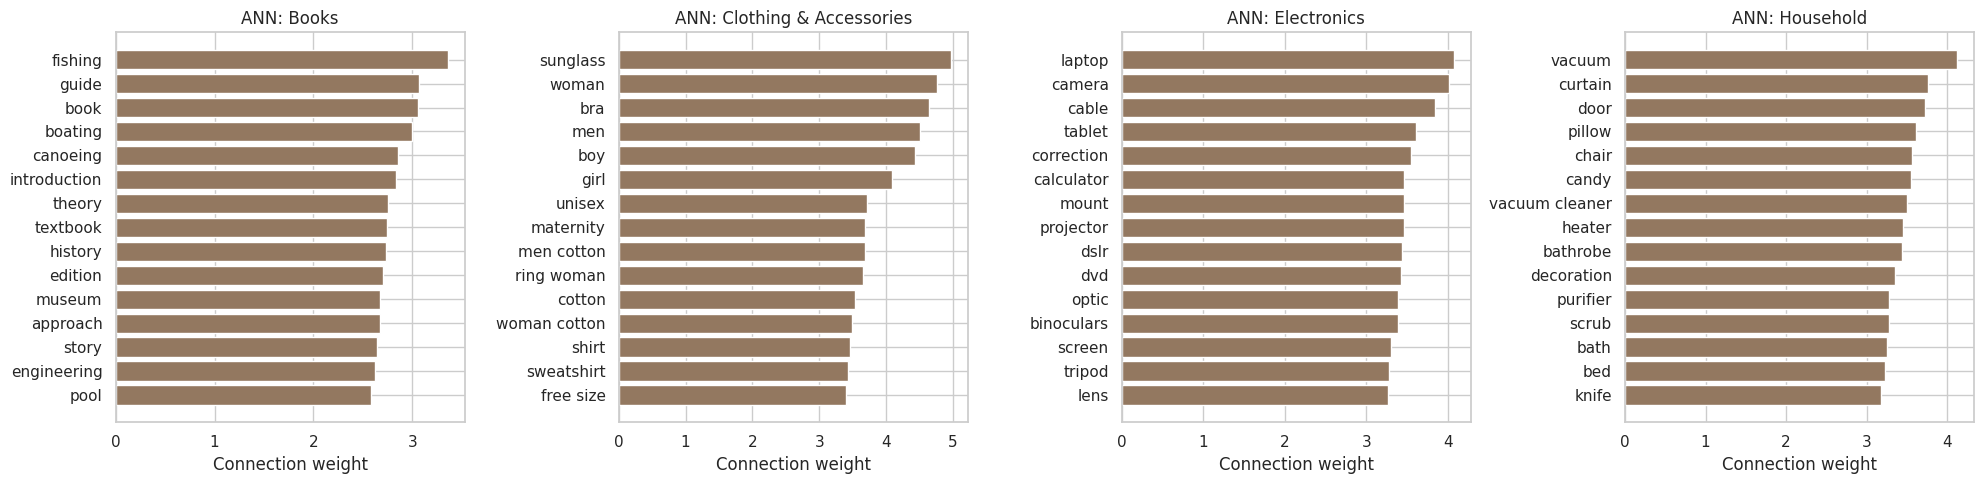

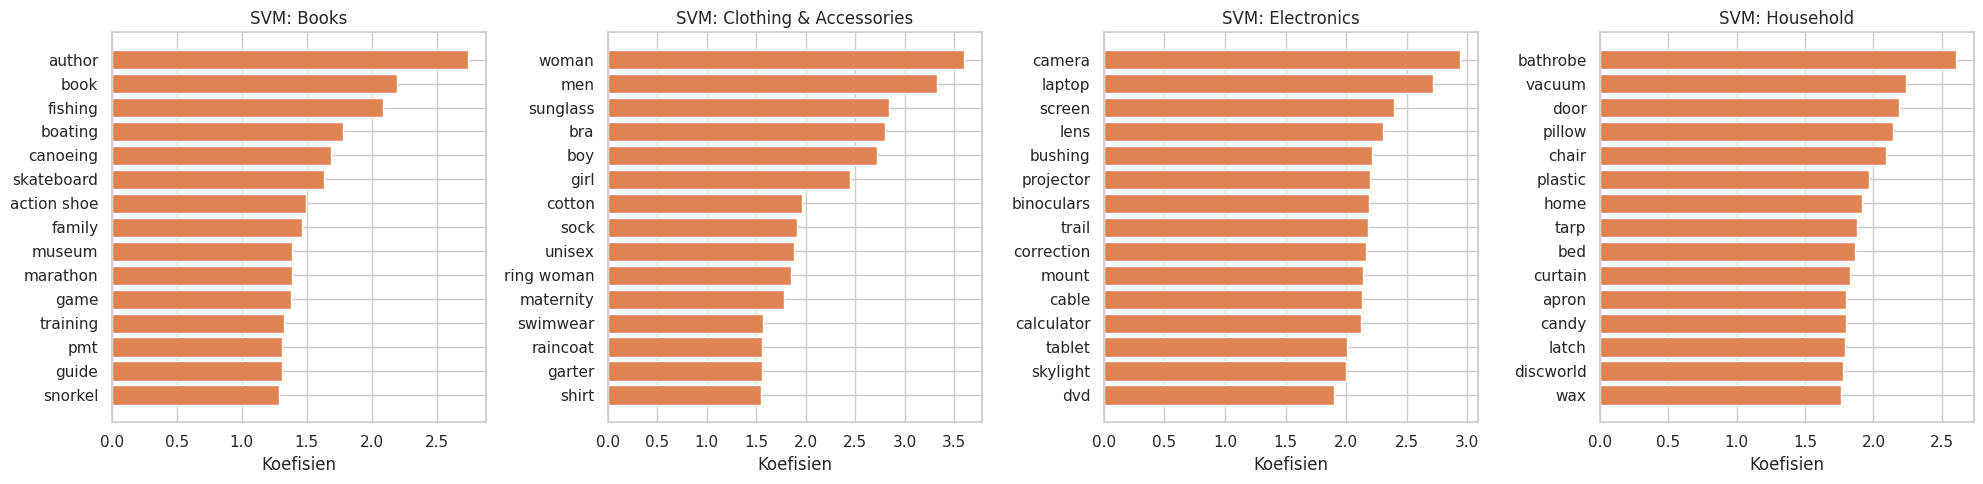

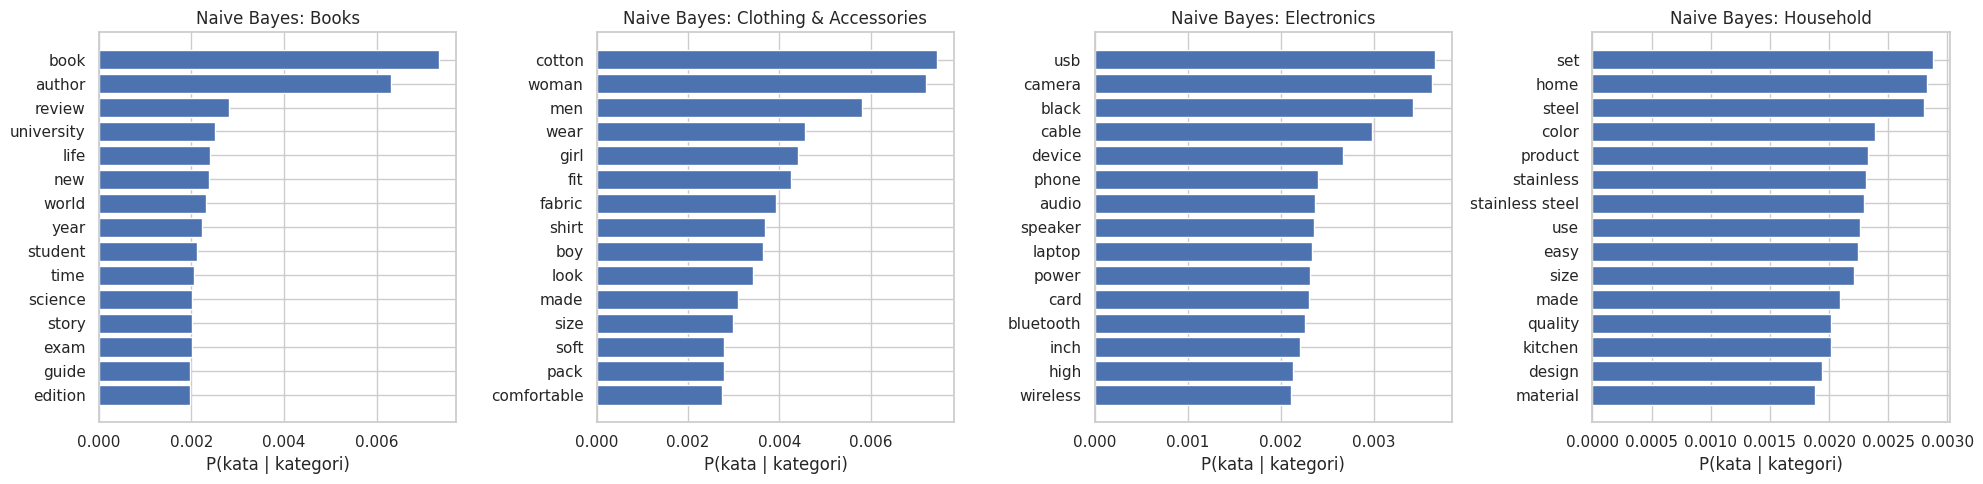

In [127]:
def plot_top_per_kategori(nama, kelas, skor, fitur, xlabel, file):
    # skor: matriks (n_kelas, n_fitur); tampilkan TOP_K kata tertinggi tiap kategori
    fig, axes = plt.subplots(1, len(kelas), figsize=(5 * len(kelas), 5))
    for ax, (i, kat) in zip(axes, enumerate(kelas)):
        idx = np.argsort(skor[i])[::-1][:TOP_K]
        ax.barh(fitur[idx][::-1], skor[i][idx][::-1], color=MODEL_COLORS[nama])
        ax.set_title(f"{nama}: {kat}"); ax.set_xlabel(xlabel)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{file}", dpi=150); plt.show()

plot_top_per_kategori("ANN", kelas_ann, bobot_ann, fitur_ann, "Connection weight", "interpretasi_ann.png")
plot_top_per_kategori("SVM", svm_clf.classes_, svm_clf.coef_, fitur_svm, "Koefisien", "interpretasi_svm.png")
plot_top_per_kategori("Naive Bayes", nb_clf.classes_, np.exp(nb_clf.feature_log_prob_), fitur_nb,
                      "P(kata | kategori)", "interpretasi_nb.png")

### Pembahasan kata penentu SVM

- **Books**: *author* dan *book* adalah penanda paling logis, karena deskripsi buku hampir selalu menyebut penulis. Kata seperti *guide*, *training*, dan *game* juga khas buku panduan atau buku permainan. Muncul pula kata bertema olahraga dan aktivitas luar ruang (*fishing, boating, canoeing, skateboard, marathon, snorkel*). Kemungkinan ini berasal dari buku panduan hobi bertema tersebut, tetapi bisa juga produk olahraga yang salah diberi label Books. Kata seperti ini perlu dicek di data, karena model bisa "belajar" kebiasaan label yang keliru.
- **Clothing & Accessories**: kata penentunya sangat logis, yaitu target pemakai (*woman, men, boy, girl, unisex, maternity*), jenis barang (*bra, sock, sunglass, swimwear, raincoat, shirt, garter*), dan bahan (*cotton*). Ini sejalan dengan F1 kategori ini yang paling tinggi: kosakatanya khas dan jarang dipakai kategori lain.
- **Electronics**: didominasi nama perangkat (*camera, laptop, screen, lens, projector, binoculars, tablet, calculator, cable, dvd*), jadi logis. Ada kata yang kurang intuitif seperti *bushing*, *trail*, *correction*, dan *skylight*. Kemungkinan berasal dari produk spesifik (misalnya *trail camera* atau filter lensa *skylight*), sehingga bobotnya tinggi karena hanya muncul di sedikit dokumen Electronics.
- **Household**: berisi perabot dan perlengkapan rumah (*vacuum, door, pillow, chair, bed, curtain, home, apron, latch*). *Bathrobe* masuk Household, bukan Clothing, karena di dataset ini produk tekstil kamar mandi dikelompokkan sebagai perlengkapan rumah. Ini salah satu sumber kebingungan Household dengan Clothing. Kata *discworld* (judul seri novel) justru muncul sebagai penanda Household, yang mengindikasikan ada buku yang salah diberi label Household.

**Arti praktis:** model terbaik mengandalkan kata benda yang spesifik untuk jenis produk, bukan kata umum seperti *quality* atau *new*. Untuk platform e-commerce, ini berarti:
1. Penjual yang menulis judul/deskripsi dengan nama jenis produk yang jelas akan lebih mudah dikategorikan otomatis.
2. Kata yang tidak intuitif (*fishing* di Books, *bushing* di Electronics, *discworld* di Household) bisa dipakai sebagai pemicu audit label.
3. Kategori dengan kosakata yang tumpang tindih (Books–Household, Electronics–Household) tetap butuh pengecekan manual, sejalan dengan confusion matrix.

In [128]:
# Kata yang muncul di top-K lebih dari satu kategori (kata "umum") per model
top_per_model = {"ANN": top_ann, "Naive Bayes": top_nb, "SVM": top_svm}
for name, top in top_per_model.items():
    hitung = Counter(w for ws in top.values() for w in ws)
    kata_umum = {w: [k for k, ws in top.items() if w in ws] for w, n in hitung.items() if n > 1}
    print(f"\nKata top-{TOP_K} {name} yang muncul di >1 kategori:")
    if not kata_umum:
        print("  tidak ada")
    for w, ks in kata_umum.items():
        print(f"  {w:20s} -> {ks}")


Kata top-15 ANN yang muncul di >1 kategori:
  tidak ada

Kata top-15 Naive Bayes yang muncul di >1 kategori:
  made                 -> [np.str_('Clothing & Accessories'), np.str_('Household')]
  size                 -> [np.str_('Clothing & Accessories'), np.str_('Household')]

Kata top-15 SVM yang muncul di >1 kategori:
  tidak ada


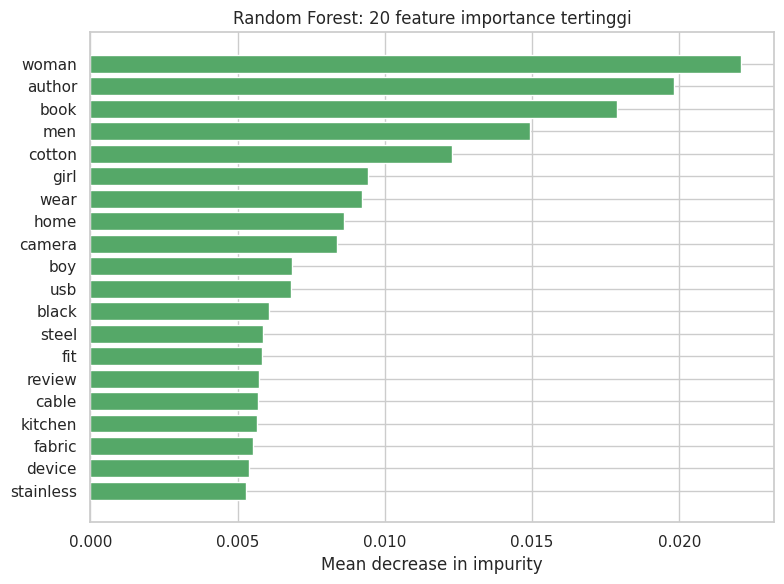

,kata,importance
0,woman,0.022104
1,author,0.019821
2,book,0.017865
3,men,0.014938
4,cotton,0.012263
5,girl,0.009437
6,wear,0.009213
7,home,0.008623
8,camera,0.008393
9,boy,0.006846


In [129]:
rf_clf = rf_pipe.named_steps["clf"]
idx_rf = np.argsort(rf_clf.feature_importances_)[::-1][:20]
top_rf = pd.DataFrame({"kata": fitur_rf[idx_rf], "importance": rf_clf.feature_importances_[idx_rf]})

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_rf["kata"][::-1], top_rf["importance"][::-1], color=MODEL_COLORS["Random Forest"])
ax.set_title("Random Forest: 20 feature importance tertinggi"); ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/interpretasi_rf.png", dpi=150); plt.show()
top_rf

In [130]:
# Random Forest: kategori dominan untuk tiap kata top-20
# Persentase dokumen latih yang mengandung kata tersebut, per kategori
Xtr_rf = rf_pipe.named_steps["tfidf"].transform(X_train)
ada_kata = (Xtr_rf[:, idx_rf] > 0).toarray()               # (n_dokumen, 20)
kelas_rf = rf_clf.classes_
jumlah = pd.DataFrame({k: ada_kata[(y_train == k).values].sum(axis=0) for k in kelas_rf},
                      index=fitur_rf[idx_rf])
persen = jumlah.div(jumlah.sum(axis=1), axis=0) * 100

tabel_rf_dominan = persen.round(1)
tabel_rf_dominan.insert(0, "importance", rf_clf.feature_importances_[idx_rf].round(4))
tabel_rf_dominan["kategori_dominan"] = persen.idxmax(axis=1)
tabel_rf_dominan["porsi_dominan (%)"] = persen.max(axis=1).round(1)
tabel_rf_dominan.index.name = "kata"
print("Kolom kategori = % dokumen latih yang mengandung kata tersebut")
tabel_rf_dominan

Kolom kategori = % dokumen latih yang mengandung kata tersebut


,importance,Books,Clothing & Accessories,Electronics,Household,kategori_dominan,porsi_dominan (%)
kata,,,,,,,
woman,0.0221,8.5,84.2,1.5,5.8,Clothing & Accessories,84.2
author,0.0198,96.9,0.2,1.7,1.2,Books,96.9
book,0.0179,89.2,0.4,4.0,6.5,Books,89.2
men,0.0149,9.3,82.3,2.0,6.3,Clothing & Accessories,82.3
cotton,0.0123,0.5,77.4,0.7,21.4,Clothing & Accessories,77.4
girl,0.0094,6.5,84.0,0.8,8.7,Clothing & Accessories,84.0
wear,0.0092,1.9,84.4,5.0,8.7,Clothing & Accessories,84.4
home,0.0086,6.9,3.1,15.8,74.3,Household,74.3
camera,0.0084,1.3,3.5,90.0,5.2,Electronics,90.0


In [131]:
# Apakah keempat model "melihat" kata yang sama?
# ANN, SVM & NB per kategori, RF global -> bandingkan himpunan gabungan top kata
from itertools import combinations

set_kata = {name: set(w for ws in top.values() for w in ws) for name, top in top_per_model.items()}
set_kata["Random Forest"] = set(top_rf["kata"])

def jaccard(a, b):
    return len(a & b) / len(a | b)

print("Jumlah kata unik:", ", ".join(f"{n}={len(set_kata[n])}" for n in MODEL_NAMES))
tabel_jaccard = pd.DataFrame({a: {b: jaccard(set_kata[a], set_kata[b]) for b in MODEL_NAMES}
                              for a in MODEL_NAMES})
print("Jaccard similarity antar model:")
display(tabel_jaccard.round(3))

print("Kata yang dipilih keempat model:", sorted(set.intersection(*set_kata.values())))
for name in top_per_model:
    print(f"Kata RF yang juga ada di {name:12s}:", sorted(set_kata["Random Forest"] & set_kata[name]))

print("\nOverlap per kategori (dari top-K tiap kategori):")
for kat in svm_clf.classes_:
    print(f"  {kat}")
    for a, b in combinations(top_per_model, 2):
        irisan = set(top_per_model[a][kat]) & set(top_per_model[b][kat])
        print(f"    {a} vs {b}: {len(irisan)}/{TOP_K} -> {sorted(irisan)}")

Jumlah kata unik: ANN=60, Naive Bayes=58, SVM=60, Random Forest=20
Jaccard similarity antar model:


,ANN,Naive Bayes,SVM,Random Forest
ANN,1.000,0.124,0.446,0.111
Naive Bayes,0.124,1.000,0.124,0.345
SVM,0.446,0.124,1.000,0.143
Random Forest,0.111,0.345,0.143,1.000


Kata yang dipilih keempat model: ['book', 'boy', 'cable', 'camera', 'cotton', 'girl', 'men', 'woman']
Kata RF yang juga ada di ANN         : ['book', 'boy', 'cable', 'camera', 'cotton', 'girl', 'men', 'woman']
Kata RF yang juga ada di Naive Bayes : ['author', 'black', 'book', 'boy', 'cable', 'camera', 'cotton', 'device', 'fabric', 'fit', 'girl', 'home', 'kitchen', 'men', 'review', 'stainless', 'steel', 'usb', 'wear', 'woman']
Kata RF yang juga ada di SVM         : ['author', 'book', 'boy', 'cable', 'camera', 'cotton', 'girl', 'home', 'men', 'woman']

Overlap per kategori (dari top-K tiap kategori):
  Books
    ANN vs Naive Bayes: 4/15 -> ['book', 'edition', 'guide', 'story']
    ANN vs SVM: 6/15 -> ['boating', 'book', 'canoeing', 'fishing', 'guide', 'museum']
    Naive Bayes vs SVM: 3/15 -> ['author', 'book', 'guide']
  Clothing & Accessories
    ANN vs Naive Bayes: 6/15 -> ['boy', 'cotton', 'girl', 'men', 'shirt', 'woman']
    ANN vs SVM: 11/15 -> ['boy', 'bra', 'cotton', 'girl', 'mat

### Perbandingan ringkas NB, RF, dan ANN dengan SVM

- **Yang sama**: model-model sepakat pada kata inti tiap kategori, seperti *book/author* (Books), *woman/men/girl/boy/cotton* (Clothing), *camera* (Electronics), dan *home* (Household). Kata inti inilah yang membuat keempat kategori relatif mudah dipisahkan.
- **Naive Bayes**: menonjolkan kata yang *sering* muncul, termasuk kata umum yang tidak khas satu kategori (misalnya *review, new, world, set, color, product, use, size, black*). Karena itu irisannya dengan SVM kecil. Ini juga menjelaskan mengapa NB sedikit di bawah SVM: sebagian keputusannya bergantung pada kata yang kurang membedakan.
- **Random Forest**: feature importance-nya lebih mirip NB daripada SVM (lihat tabel Jaccard), karena pohon keputusan cenderung memilih kata yang sering muncul supaya bisa memisahkan banyak data sekaligus. Tabel kategori dominan menunjukkan apakah kata penting RF benar-benar khas satu kategori (porsi dominan tinggi) atau tersebar (porsi dominan rendah).
- **ANN**: bandingkan tabel connection weights dengan SVM. Jika irisannya besar, ANN pada dasarnya bersandar pada kata kunci yang sama dengan SVM, sehingga kapasitas non-linearnya tidak banyak menambah informasi. Ini sejalan dengan skor F1 keduanya yang hampir sama. Hasil ini adalah pendekatan, karena ANN bersifat *black box*.
- **Kesimpulan**: SVM unggul karena memberi bobot tinggi pada kata yang *spesifik* untuk satu kategori, sedangkan NB dan RF lebih bergantung pada kata yang *sering* muncul.

> Isi poin ANN dan angka irisan/Jaccard setelah sel di atas dijalankan.

## Tahap 11. Analisis Error

Data uji yang **salah diklasifikasi oleh keempat model sekaligus** menunjukkan keterbatasan pendekatan (representasi bag-of-words / kualitas data), bukan kelemahan satu algoritma.

In [132]:
err = pd.DataFrame({"text": df.loc[X_test.index, "text"].values,
                    "clean": X_test.values, "label": y_test.values})
for name in MODEL_NAMES:
    err[f"pred_{name}"] = hasil[name]["y_pred"]
pred_cols = [f"pred_{n}" for n in MODEL_NAMES]

salah_semua = err[(err[pred_cols].ne(err["label"], axis=0)).all(axis=1)].copy()
print(f"Salah oleh keempat model: {len(salah_semua)} dari {len(err)} data uji "
      f"({len(salah_semua) / len(err):.2%})")

for name in MODEL_NAMES:
    print(f"  Salah oleh {name:14s}: {(err[f'pred_{name}'] != err['label']).sum()}")

Salah oleh keempat model: 146 dari 5561 data uji (2.63%)
  Salah oleh ANN           : 233
  Salah oleh Naive Bayes   : 312
  Salah oleh SVM           : 221
  Salah oleh Random Forest : 376


In [133]:
# Kategori asli vs prediksi (pakai prediksi SVM sebagai wakil) untuk error bersama
salah_semua["sepakat"] = salah_semua[pred_cols].nunique(axis=1) == 1
salah_semua["n_kata_clean"] = salah_semua["clean"].str.split().str.len()
print("Keempat model memprediksi label (salah) yang SAMA:", salah_semua["sepakat"].sum())
pd.crosstab(salah_semua["label"], salah_semua["pred_SVM"],
            rownames=["Label asli"], colnames=["Prediksi SVM"])

Keempat model memprediksi label (salah) yang SAMA: 128


Prediksi SVM,Books,Clothing & Accessories,Electronics,Household
Label asli,,,,
Books,0,8,17,41
Clothing & Accessories,4,0,2,7
Electronics,9,1,0,28
Household,13,5,11,0


### Pengelompokan penyebab error

Pengelompokan otomatis di bawah hanya **heuristik awal** untuk membantu pembacaan manual:

- **Deskripsi pendek / kurang informatif**: setelah preprocessing tersisa ≤ 10 kata.
- **Kemungkinan label salah**: keempat model sepakat pada label yang sama (tetapi berbeda dari label asli) dan SVM sangat yakin (selisih skor keputusan antara prediksi dan label asli besar).
- **Produk ambigu**: sisanya, misalnya model tidak sepakat atau deskripsi memuat kata dari dua kategori (contoh: buku resep → *Books* atau *Household*?).

Hasil akhir untuk paper sebaiknya diverifikasi dengan **membaca contohnya satu per satu**.

In [134]:
# Margin keputusan SVM: skor kelas prediksi - skor kelas asli
dec = svm_pipe.decision_function(salah_semua["clean"])
kelas = list(svm_clf.classes_)
idx_pred = [kelas.index(p) for p in salah_semua["pred_SVM"]]
idx_asli = [kelas.index(l) for l in salah_semua["label"]]
salah_semua["margin_svm"] = dec[np.arange(len(dec)), idx_pred] - dec[np.arange(len(dec)), idx_asli]

AMBANG_PENDEK = 10
AMBANG_MARGIN = salah_semua["margin_svm"].quantile(0.75) if len(salah_semua) else 0

def kelompok(r):
    if r["n_kata_clean"] <= AMBANG_PENDEK:
        return "Deskripsi pendek / kurang informatif"
    if r["sepakat"] and r["margin_svm"] >= AMBANG_MARGIN:
        return "Kemungkinan label salah"
    return "Produk ambigu"

salah_semua["penyebab"] = salah_semua.apply(kelompok, axis=1)
print(f"Ambang margin SVM (kuartil atas) = {AMBANG_MARGIN:.3f}")
salah_semua["penyebab"].value_counts().to_frame("jumlah")

Ambang margin SVM (kuartil atas) = 1.818


,jumlah
penyebab,
Produk ambigu,103
Kemungkinan label salah,33
Deskripsi pendek / kurang informatif,10


In [135]:
# Contoh tiap kelompok untuk dibaca manual
kolom_tampil = ["label"] + pred_cols + ["n_kata_clean", "margin_svm", "text"]
for kel in salah_semua["penyebab"].unique():
    print(f"\n===== {kel} =====")
    display(salah_semua[salah_semua["penyebab"] == kel]
            .sort_values("margin_svm", ascending=False)[kolom_tampil].head(5)
            .assign(text=lambda d: d["text"].str[:250]))


===== Produk ambigu =====


,label,pred_ANN,pred_Naive Bayes,pred_SVM,pred_Random Forest,n_kata_clean,margin_svm,text
4992,Clothing & Accessories,Books,Household,Books,Household,27,2.200118,"Quechua Arpenaz Hiking Backpack 10 L ( Mint Green) Made for hikers of 10 years and older, hiking several hours on level ground. This 10 L hiking backpack is ideal for hikers who want to hike a cou..."
1453,Electronics,Household,Books,Books,Household,67,1.824948,Posterhouzz Fantastic Beasts: The Crimes of Grindelwald Johnny Depp Jude Law Albus Dumbledore Ezra Miller Credence Barebone Claudia Kim Maledictus Zoë Kravitz Leta Lestrange Callum Turner Theseus ...
8,Books,Electronics,Electronics,Electronics,Household,83,1.817573,"Flashforge Adventurer 3 3D Printer This is newly introduced 3d printer by flashforge known as adventurer 3. The features of the product as follows: Build size:-150x150x150mm,patented removable ext..."
2568,Books,Household,Household,Household,Household,53,1.803942,Kuber Industries Cotton Refrigerator Cover Set - Maroon Kuber Industries has the experience and expertise to minimise wastage of steel by the use of Type II Kuber couplers for your construction ne...
5115,Books,Household,Household,Household,Household,22,1.711315,P S Retail Sweet Home Mini Resin Crafts Fairy Garden Miniatures (6 pcs Set) P S Retail Sweet Home Mini Resin Crafts Fairy Garden Miniatures (6 pcs Set)



===== Deskripsi pendek / kurang informatif =====


,label,pred_ANN,pred_Naive Bayes,pred_SVM,pred_Random Forest,n_kata_clean,margin_svm,text
3061,Electronics,Books,Books,Books,Books,6,2.099569,Drishti To The Point 2018 BOOK FOR UPSC MAINS EXAM
3600,Books,Clothing & Accessories,Clothing & Accessories,Clothing & Accessories,Clothing & Accessories,3,1.868433,Under Armour Women's Cap
3324,Clothing & Accessories,Books,Books,Books,Books,3,1.137623,Daughters Of Time ...
1406,Electronics,Household,Household,Household,Household,6,1.084307,"Klaxon Wooden TV Unit (Matte Finish, Black)"
365,Electronics,Books,Household,Books,Books,6,0.854296,Webcam HD 4310**New Retail** Webcam HD 4310**New Retail**



===== Kemungkinan label salah =====


,label,pred_ANN,pred_Naive Bayes,pred_SVM,pred_Random Forest,n_kata_clean,margin_svm,text
4915,Books,Electronics,Electronics,Electronics,Electronics,100,3.650390,"Neewer 90084038 12-in-1 Sport Accessory Kit for GoPro (Black) For xiaomi yi and other action cameras, there need another conversion adapter to mount on those accessories (conversion adapter is not..."
1822,Books,Electronics,Electronics,Electronics,Electronics,159,3.201877,"Toreto Magnetic Wireless Music Speaker Twin MAGNO 2""-TOR 322 Toreto Provides The Premium Quality And Affordable Brands In The World. Focus On Offering Chargers/ Cables, Bluetooth Speakers, Headpho..."
5091,Electronics,Household,Household,Household,Household,93,3.195315,"Kitchen Point Lovely Cartoon Shape Plastic and Steel Mini Non-Stick Pan for Pancake Egg Frying Color Name:Mini Omlet Pan Exciting Sunny morning, to the children love to do a nutritious creative ..."
4101,Books,Household,Household,Household,Household,111,3.130350,Ariel Matic Top Load Detergent Washing Powder - 3 kg (Rupees 150 Off) Size:3kg | Style na...
3137,Household,Electronics,Electronics,Electronics,Electronics,97,3.126924,QXN PRO - BNC Connector with Copper Wire Moulded - 10PCS - 18CM - BNC Golden Male Plug Cable (White) Delivers high performance and versatile video for your AV audio video device equipment; Accurat...


In [136]:
# Ekspor semua error bersama untuk dibaca manual
salah_semua[kolom_tampil + ["penyebab"]].to_csv(f"{FIG_DIR}/error_keempat_model.csv", index=False)
print("Disimpan ke", f"{FIG_DIR}/error_keempat_model.csv")

Disimpan ke figures/error_keempat_model.csv


In [137]:
# Pasangan kategori yang paling sering tertukar (gabungan dua arah) per model
def pasangan_tertukar(y_true, y_pred):
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels_urut), index=labels_urut, columns=labels_urut)
    out = {}
    for i, a in enumerate(labels_urut):
        for b in labels_urut[i + 1:]:
            out[f"{a} <-> {b}"] = cm.loc[a, b] + cm.loc[b, a]
    return pd.Series(out)

tabel_tertukar = pd.DataFrame({n: pasangan_tertukar(y_test, hasil[n]["y_pred"]) for n in MODEL_NAMES})
tabel_tertukar["Error bersama (3 model)"] = pasangan_tertukar(salah_semua["label"], salah_semua["pred_SVM"])
tabel_tertukar.sort_values("SVM", ascending=False)

,ANN,Naive Bayes,SVM,Random Forest,Error bersama (3 model)
Books <-> Household,78,93,74,109,54
Electronics <-> Household,79,114,71,139,39
Books <-> Electronics,34,39,33,40,26
Clothing & Accessories <-> Household,22,39,21,50,12
Books <-> Clothing & Accessories,14,22,17,31,12
Clothing & Accessories <-> Electronics,6,5,5,7,3


## Tahap 13. Penarikan Kesimpulan

Sel berikut merangkum angka-angka utama secara otomatis agar mudah dipindahkan ke paper.

In [138]:
terbaik = tabel_eval["F1-macro"].idxmax()
tercepat_train = tabel_eval["Waktu training (s)"].idxmin()
terlambat_train = tabel_eval["Waktu training (s)"].idxmax()
tercepat_pred = tabel_eval["Waktu prediksi (s)"].idxmin()

print("=" * 80)
print("TUJUAN 1: Membangun model klasifikasi otomatis kategori produk (Tahap 1-7)")
print("=" * 80)
for k, v in log_cleaning.items():
    print(f"  {k:45s}: {v}")
print(f"  Data latih / uji                             : {len(X_train)} / {len(X_test)}")
for n in MODEL_NAMES:
    print(f"  {n:14s} best={hasil[n]['best_params']}, CV F1-macro={hasil[n]['cv_f1_macro']:.4f}")

print("\n" + "=" * 80)
print("TUJUAN 2: Membandingkan performa ANN, NB, SVM, RF (Tahap 8)")
print("=" * 80)
for n in MODEL_NAMES:
    r = tabel_eval.loc[n]
    print(f"  {n:14s} Acc={r['Accuracy']:.4f}  F1-macro={r['F1-macro']:.4f}  "
          f"train={r['Waktu training (s)']:.2f}s  prediksi={r['Waktu prediksi (s)']:.3f}s")
print(f"  Model terbaik (F1-macro uji): {terbaik}")
terbaik_cv = max(MODEL_NAMES, key=lambda n: hasil[n]["cv_f1_macro"])
print(f"  Model terbaik (CV F1-macro) : {terbaik_cv}")
print(f"  Training tercepat: {tercepat_train} | terlambat: {terlambat_train}")
print(f"  Prediksi tercepat: {tercepat_pred}")

print("\n" + "=" * 80)
print("TUJUAN 3: Kata penentu tiap kategori dan pola error (Tahap 9-10)")
print("=" * 80)
for kat in svm_clf.classes_:
    print(f"  {kat}")
    print(f"    SVM : {', '.join(top_svm[kat][:8])}")
    print(f"    ANN : {', '.join(top_ann[kat][:8])}")
    print(f"    NB  : {', '.join(top_nb[kat][:8])}")
print(f"  RF (global): {', '.join(top_rf['kata'][:8])}")
print(f"  Error bersama keempat model: {len(salah_semua)} ({len(salah_semua) / len(err):.2%} data uji)")
for n in MODEL_NAMES:
    print(f"  Pasangan paling sering tertukar ({n}): {tabel_tertukar[n].idxmax()}")

TUJUAN 1: Membangun model klasifikasi otomatis kategori produk (Tahap 1-7)
  Data awal                                    : 50425
  Setelah hapus teks kosong                    : 50424
  Setelah hapus label konflik                  : 50424
  Setelah hapus duplikat                       : 27802
  Setelah preprocessing (hapus teks kosong)    : 27802
  Data latih / uji                             : 22241 / 5561
  ANN            best={'alpha': 0.001}, CV F1-macro=0.9536
  Naive Bayes    best={'alpha': 0.01}, CV F1-macro=0.9441
  SVM            best={'C': 1}, CV F1-macro=0.9566
  Random Forest  best={'max_depth': None, 'n_estimators': 300}, CV F1-macro=0.9292

TUJUAN 2: Membandingkan performa ANN, NB, SVM, RF (Tahap 8)
  ANN            Acc=0.9581  F1-macro=0.9580  train=78.28s  prediksi=0.822s
  Naive Bayes    Acc=0.9439  F1-macro=0.9440  train=9.22s  prediksi=0.699s
  SVM            Acc=0.9603  F1-macro=0.9601  train=10.90s  prediksi=0.753s
  Random Forest  Acc=0.9324  F1-macro=0.9322  tra

### Template jawaban tujuan penelitian

Isi bagian berikut berdasarkan output sel di atas.

| Tujuan penelitian | Dijawab dari | Ringkasan temuan |
|---|---|---|
| 1. Membangun model klasifikasi otomatis kategori produk | Tahap 1–7 | Jumlah data tiap tahap pembersihan, pipeline TF-IDF + classifier, hyperparameter terbaik tiap model. |
| 2. Membandingkan performa ANN, NB, SVM, dan RF | Tahap 8 | Model dengan F1-macro tertinggi, selisih antar model, serta efisiensi waktu training dan prediksi. |
| 3. Mengidentifikasi kata penentu tiap kategori | Tahap 9–10 | Kata dengan koefisien SVM / connection weight ANN tertinggi, perbedaannya dengan kata berpeluang tinggi NB dan feature importance RF, serta pola error. |

### Panduan Discussion

- **Jika SVM unggul**: sesuai dengan karakter SVM linear yang cocok untuk data teks berdimensi tinggi dan *sparse*. Ruang fitur TF-IDF berukuran 20.000 dimensi dengan >99% nilai nol, dan pada teks sebagian besar kategori dapat dipisahkan secara linear (Joachims, 1998).
- **ANN (MLP)** dapat mempelajari hubungan non-linear antar kata, tetapi pada fitur TF-IDF yang sudah hampir terpisah linear, keunggulannya atas SVM biasanya kecil, sementara waktu training-nya jauh lebih lama dan hasilnya lebih sulit diinterpretasi. Bandingkan juga apakah kata penentu ANN mirip dengan SVM (lihat tabel Jaccard).
- **Naive Bayes** mengasumsikan setiap kata independen satu sama lain. Asumsi ini jarang benar, tetapi NB tetap kompetitif sebagai baseline karena sangat cepat dan stabil (McCallum & Nigam, 1998). Kata berpeluang tinggi NB cenderung kata *umum* (muncul di beberapa kategori), sedangkan koefisien SVM menonjolkan kata yang *membedakan*.
- **Random Forest**: pohon keputusan pada fitur sparse berdimensi tinggi hanya memakai sebagian kecil fitur di tiap split, sehingga butuh banyak pohon yang dalam. Akibatnya waktu training dan prediksinya besar. Untuk platform e-commerce yang menerima ribuan produk baru per hari dan perlu dilatih ulang secara berkala, biaya ini penting, apalagi jika akurasinya tidak lebih baik dari SVM.
- **Analisis error**: kaitkan pasangan kategori yang paling sering tertukar dengan contoh nyata (misalnya buku resep, aksesori elektronik, atau perlengkapan rumah tangga bertema pakaian).
- **Perbandingan dengan penelitian lain**: bandingkan dengan studi yang memakai dataset yang sama (E-commerce Text Dataset, Gautam, 2019, Zenodo/Kaggle) atau kombinasi TF-IDF + ANN/NB/SVM/RF lainnya. Perhatikan apakah studi tersebut menghapus duplikat; jika tidak, skornya kemungkinan lebih tinggi karena model sebagian hanya "menghafal" deskripsi yang muncul di data latih dan data uji.

**Referensi yang disebut** (periksa kembali detail sitasinya sebelum dipakai):
- Joachims, T. (1998). *Text categorization with support vector machines: Learning with many relevant features.* ECML.
- McCallum, A., & Nigam, K. (1998). *A comparison of event models for naive Bayes text classification.* AAAI Workshop on Learning for Text Categorization.
- Olden, J. D., Joy, M. K., & Death, R. G. (2004). *An accurate comparison of methods for quantifying variable importance in artificial neural networks using simulated data.* Ecological Modelling, 178(3–4).
- Gautam (2019). *E-commerce text dataset.* Zenodo.